<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project3_tsunami.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Tsunami
In this project, we will use Dedalus to model the propagation of Tsunami waves. Tsunami typically have wavelengths larger than 100km and periods of about 1 hour. Since their wavelength is much larger than the depth of the ocean, Tsunami can be modelled using the shallow water equations.

Here, we will use Dedalus to solve an initial value problem for the shallow water equations. We will generate a Tsunami using a localized disturbance to the water height.

Student tasks are in [Section 1.3]( #section1pt3 ), [Section 2.3]( #section2pt3 ), and [Section 3.3]( #section3pt3 ).

## Setup
If you are using Google colab, run the script below to install Dedalus

In [11]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

# Check if running on google colab
import os
using_google_colab = bool(os.getenv("COLAB_RELEASE_TAG"))

# Check for Dedalus
try:
    import dedalus.public as de
    print("Dedalus already installed :)")
except:
    print("Dedalus not installed yet.")
    if using_google_colab:
        print("Installing for Google Colab.")
        print()
        # Step 1: Install FFTW
        !apt-get install libfftw3-dev
        !apt-get install libfftw3-mpi-dev
        # Step 2: Set paths for Dedalus installation
        import os
        os.environ['MPI_INCLUDE_PATH'] = "/usr/lib/x86_64-linux-gnu/openmpi/include"
        os.environ['MPI_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        os.environ['FFTW_INCLUDE_PATH'] = "/usr/include"
        os.environ['FFTW_LIBRARY_PATH'] = "/usr/lib/x86_64-linux-gnu"
        # Step 3: Install Dedalus using pip
        !pip3 install cython mpi4py numpy setuptools wheel
        !CC=mpicc pip3 install --no-cache --no-build-isolation http://github.com/dedalusproject/dedalus/zipball/master/
        !pip3 install -q ipympl
        # Step 4: Check installation
        print()
        try:
            import dedalus.public as de
            print("Dedalus successfully installed :)")
        except:
            print("Error installing Dedalus :(")
            raise
    else:
        print("See website for installation instructions:")
        print("https://dedalus-project.readthedocs.io/en/latest/pages/installation.html")

# Setup interactive matplotlib
if using_google_colab:
    from google.colab import output
    output.enable_custom_widget_manager()

env: OMP_NUM_THREADS=1
env: NUMEXPR_MAX_THREADS=1
Dedalus already installed :)


## 1.  1D shallow water equations
Let's start by solving the shallow water equations in 1D with periodic boundary conditions in our spatial variable, $x$. The script below solves the following equations:

$$ \partial_t u + g \partial_x(h) = - u\partial_x u$$
$$ \partial_t h + \partial_x(Hu) = -\partial_x(hu)$$

In these equations, $g$ is the constant gravitational acceleration, $u$ is the velocity in the $x$ direction, $H$ is the resting height, and $h$ is the height of the free surface relative to $H$. Note that the terms on the right hand side are nonlinear in our dependent variables, and we will use an explicit timestepping method for these terms. Recall that Dedalus uses explicit timestepping for terms on the right hand side of the inputted equation.

Because we are interested in an application to Tsunami, we will solve the equations using dimensional variables. It is convenient to define simulation units at the start of the script so that we can be explicit about the units.

We will start with the following initial conditions:
$$ h=e^{-(x-x_1)^2/w_1^2} $$
$$ u=0 $$
where $x_1$ is the center and $w_1=100$ km is the width of the Gaussian perturbation.

To see how the waves change as they approach shallow water, we will set the resting water depth to include a localized seamount using the form:
$$ H=H_0-(H_0-H_{min})e^{(-(x-x_2)^2/w_2^2)} $$
where $x_2$ is the location of the seamount, $H_0=4$ km is the depth of the ocean away from the seamount, and $H_{min}$ is the minimum water depth above the seamount. Note that since $H\ll w$, the shallow water approximation is appropriate here.

### 1.1  Dedalus script to solve the 1D shallow water equations

The script below solves the 1D shallow water equations with the initial conditions given above.

In [12]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size
Nx = 512 # The number of gridpoints in x
g = 9.81 * meter / second**2 # Gravitational acceleration
H0 = 4 * kilometer # Reference ocean depth
w1 = 20 * kilometer # Width of the initial perturbation
x1 = 200 * kilometer # Center of the initial perturbation
x2 = 500 * kilometer # Center of the seamount
w2 = 100 * kilometer # Width of the seamount
H_min = 100 * meter # minimum depth above the seamount

timestep = 60 * second # Specify the timestep
stop_sim_time = 100 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Create an x-coordinate, a corresponding basis, and a distributor
xcoord = dedalus.Coordinate('x')
dist = dedalus.Distributor(xcoord, dtype=np.float64) # No mesh for serial / automatic parallelization
x_basis = dedalus.RealFourier(xcoord, size=Nx, bounds=(0, Lx))
x = dist.local_grid(x_basis)

# Specify the Fields and set the initial conditions
u = dist.Field(name='u', bases=x_basis)
h = dist.Field(name='h', bases=x_basis)
H = dist.Field(name='H', bases=x_basis)
h.change_scales(1)
H.change_scales(1)
u.change_scales(1)
H['g'] = H0-(H0-H_min)*np.exp(-(x-x2)**2.0/w2**2.0)
h['g'] = np.exp(-(x-x1)**2.0/w1**2.0)  # Initialize the height with a Gaussian function with width set above
u['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, xcoord)

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u)")
problem.add_equation("dt(h) + dx(H*u) = - dx(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save=np.array(h_save) # convert h_save to an np.array type to allow data slicing

INFO:subsystems:Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.3e+01/s


2026-11-21 20:22:51,821 subsystems 0/1 INFO :: Building subproblem matrices 1/1 (~100%) Elapsed: 0s, Remaining: 0s, Rate: 1.3e+01/s


INFO:__main__:Starting main loop


2026-11-21 20:22:51,834 __main__ 0/1 INFO :: Starting main loop


INFO:solvers:Simulation stop time reached.


2026-11-21 20:22:52,182 solvers 0/1 INFO :: Simulation stop time reached.


... (10 outputs left out)

INFO:solvers:CPU time (iter 10-end): 6.479e-05 cpu-hr


2026-11-21 20:22:52,194 solvers 0/1 INFO :: CPU time (iter 10-end): 6.479e-05 cpu-hr


INFO:solvers:Speed: 7.887e+05 mode-stages/cpu-sec


2026-11-21 20:22:52,197 solvers 0/1 INFO :: Speed: 7.887e+05 mode-stages/cpu-sec


### 1.2  Plotting
The code below will make a movie of the height.

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 20:22:52,389 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp3nwcsvfj/temp.m4v


2026-11-21 20:22:52,392 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp3nwcsvfj/temp.m4v


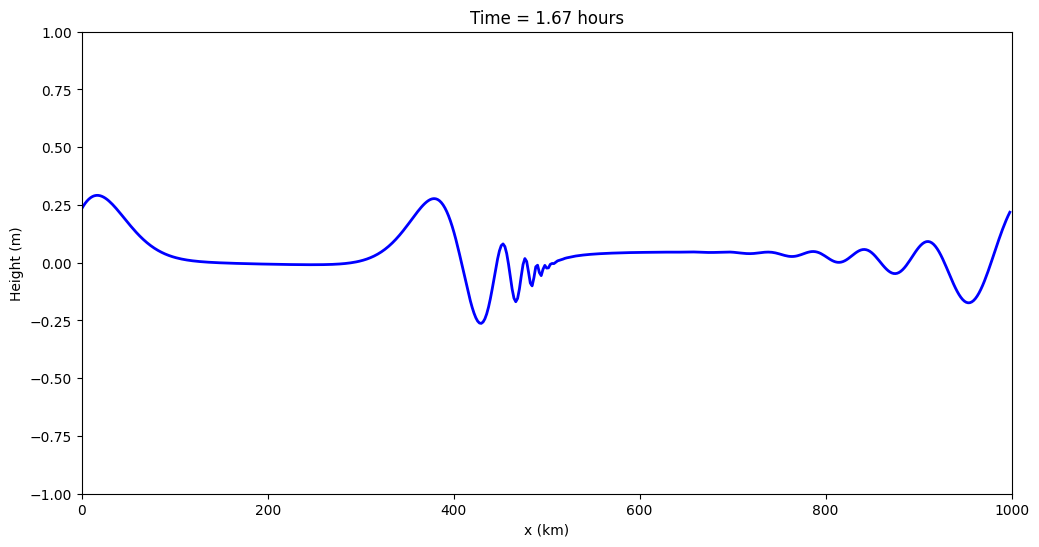

In [13]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Specify the axis limits and labels
plt.xlim((0, Lx / (1*kilometer)))
plt.ylim((-1, 1))
plt.xlabel('x (km)')
plt.ylabel('Height (m)')

# Create objects that will change during the animation
txt_title = plt.title('')
height, = plt.plot([], [], 'b', lw=2)

# Define an animation function
def drawframe(n):
    height.set_data(x/(1*kilometer), h_save[n,:])
    txt_title.set_text('Time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())


---

### 1.3 Student investigation
<a id='section1pt3'></a>
In the cells below, provide an expression for the expected wave speed and state any assumptions that are necessary to arrive at this. Then plot the wave speed from the output above and compare this with the expected value.

For a right-moving shallow-water wave, the expected local wave speed is

$$
c(x)=\sqrt{gH(x)},
$$

where $g$ is gravitational acceleration and $H(x)$ is the undisturbed water depth.

This result assumes that the wavelength is much greater than the water depth, the surface displacement is small compared with the depth ($|h|\ll H$), and the background water is at rest. For constant depth, the linearized shallow-water equations are $u_t=-g h_x$ and $h_t=-H u_x$. Combining them gives $h_{tt}=gHh_{xx}$, a wave equation with speed $\sqrt{gH}$. Over the seamount, we use this speed locally, assuming that the depth changes gradually across the wave.

With $g=9.81\ \mathrm{m\,s^{-2}}$, the predicted speed decreases from approximately $198\ \mathrm{m\,s^{-1}}$ in water of depth $4000\ \mathrm{m}$ to $31.3\ \mathrm{m\,s^{-1}}$ at the summit, where the depth is $100\ \mathrm{m}$.

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 20:23:11,129 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpmzrelj_s/temp.m4v


2026-11-21 20:23:11,132 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpmzrelj_s/temp.m4v


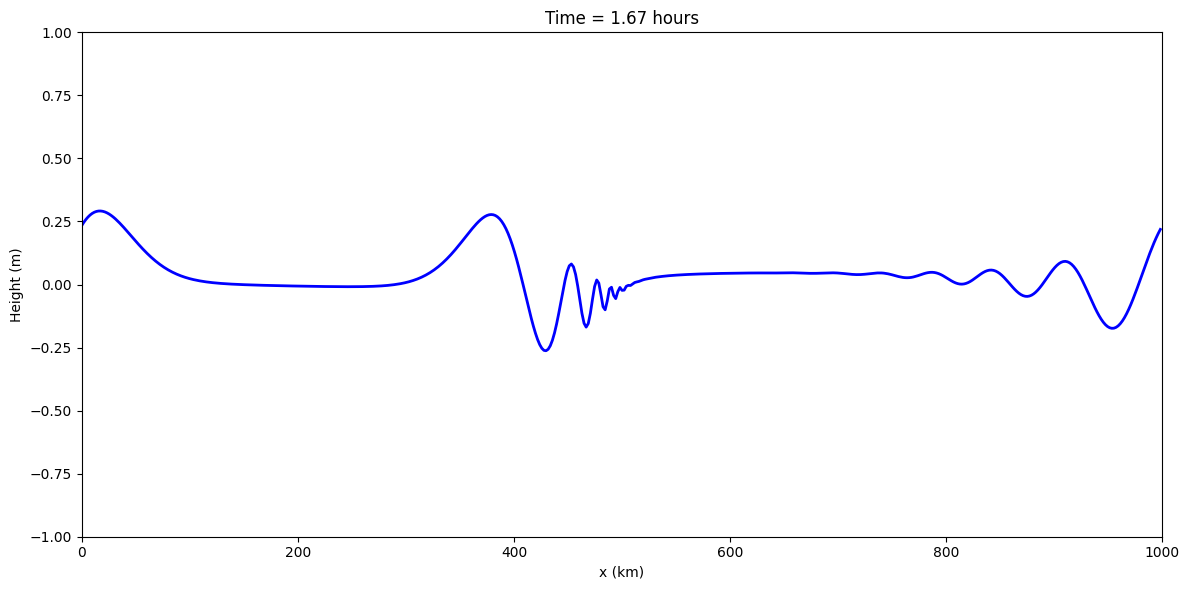

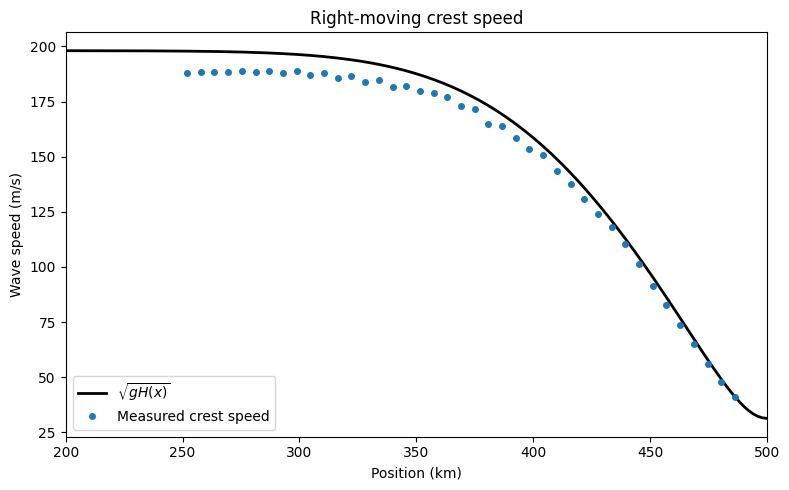

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

x_grid = np.asarray(x).ravel()
times = np.asarray(t_save)
heights = np.asarray(h_save)

if heights.shape != (times.size, x_grid.size):
    raise ValueError("Run Section 1.1 before this cell.")

depth = np.asarray(H["g"]).ravel()
x_km = x_grid / kilometer

def setup_height_axis(ax):
    ax.set(
        xlim=(0, Lx / kilometer),
        ylim=(-1, 1),
        xlabel="x (km)",
        ylabel="Height (m)"
    )

fig_video, ax_video = plt.subplots(figsize=(12, 6))
setup_height_axis(ax_video)
height_line, = ax_video.plot([], [], "b-", lw=2)
time_title = ax_video.set_title("")

def drawframe(n):
    height_line.set_data(x_km, heights[n])
    time_title.set_text(f"Time = {times[n] / hour:.2f} hours")
    return height_line, time_title

anim = animation.FuncAnimation(
    fig_video, drawframe, frames=times.size, interval=40, blit=True
)
plt.close(fig_video)
display(HTML(anim.to_html5_video()))

fig_height, ax_height = plt.subplots(figsize=(12, 6))
setup_height_axis(ax_height)
ax_height.plot(x_km, heights[-1], "b-", lw=2)
ax_height.set_title(f"Time = {times[-1] / hour:.2f} hours")
fig_height.tight_layout()
plt.show()

stations = np.flatnonzero((x_grid >= x1 + 2 * w1) & (x_grid <= x2))[::3]
positions = []
arrivals = []

for j in stations:
    signal = heights[:, j]
    peaks = np.flatnonzero(
        (signal[1:-1] > signal[:-2])
        & (signal[1:-1] >= signal[2:])
        & (signal[1:-1] > 0.1)
    ) + 1

    if peaks.size == 0:
        continue

    k = peaks[0]
    local_times = times[k - 1:k + 2] - times[k]
    a, b, _ = np.polyfit(local_times, signal[k - 1:k + 2], 2)
    positions.append(x_grid[j])
    arrivals.append(times[k] - b / (2 * a))

positions = np.asarray(positions)
arrivals = np.asarray(arrivals)

if positions.size < 5:
    raise ValueError("Too few crests were detected.")

centres_km = positions[2:-2] / kilometer
speeds = []

for j in range(2, positions.size - 2):
    window = slice(j - 2, j + 3)
    offsets = positions[window] - positions[j]
    slope = np.polyfit(offsets, arrivals[window], 1)[0]
    speeds.append(1 / slope if slope > 0 else np.nan)

region = (x_grid >= x1) & (x_grid <= x2)
theory = np.sqrt(g * depth[region])

fig_speed, ax_speed = plt.subplots(figsize=(8, 5))
ax_speed.plot(x_km[region], theory, "k-", lw=2, label=r"$\sqrt{gH(x)}$")
ax_speed.plot(centres_km, speeds, "o", ms=4, label="Measured crest speed")
ax_speed.set(
    xlim=(x1 / kilometer, x2 / kilometer),
    xlabel="Position (km)",
    ylabel="Wave speed (m/s)",
    title="Right-moving crest speed"
)
ax_speed.legend(loc="lower left")
fig_speed.tight_layout()
plt.show()

### Discussion:
The right-moving crest slows down as it approaches the seamount, consistent with the shallow-water prediction $c(x)=\sqrt{gH(x)}$. At $x\approx250$ km, the measured speed is about $188\ \mathrm{m\,s^{-1}}$, roughly 5% below the predicted $198\ \mathrm{m\,s^{-1}}$. The two curves agree more closely farther up the slope. At the last measurement near $x=487$ km, both give approximately $41\ \mathrm{m\,s^{-1}}$. The theoretical speed falls to $31.3\ \mathrm{m\,s^{-1}}$ at the summit ($x=500$ km), beyond the last measured point.

The small difference in deeper water may partly reflect the finite time step of the simulation and the way the crest speed was measured. Each measured speed comes from arrival times across five neighbouring stations, while the theoretical curve gives the speed at a single position. Overall, the simulation captures both the direction and the magnitude of the slowdown as the water becomes shallower.

---

## 2.  2D Shallow water equations

Now, let's see how things change if we move to two dimensions. The script below solves the 2D shallow water equations:

$$ \partial_t u + g \partial_x(h) = - u*\partial_x u - v*\partial_y u$$
$$ \partial_t u + g \partial_y(h) = - u*\partial_x v - v*\partial_y v$$
$$ \partial_t h + H (\partial_x(u) + \partial_y(v)) = -\partial_x(h*u) - \partial_y(h*v)$$

We will solve these equations in a square domain with periodic boundary conditions. We will again initialize with a Gaussian height disturbance and with no water motion, but this time in 2D:

$$ h=e^{-(x^2+y^2)/w^2} $$
$$ u=0 $$
$$ v=0 $$

### 2.1  Dedalus script to solve the 2D shallow water equations

In [22]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Specify the simulation parameters
Lx = 1000 * kilometer # The domain size in x
Ly = 1000 * kilometer # The domain size in y
Nx = 64 # The number of gridpoints in x
Ny = 64 # The number of gridpoints in y
g = 9.81 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Reference ocean depth
width = 100 * kilometer # Set the width of the initial Gaussian

timestep = 60 * second # Specify the timestep
stop_sim_time = 30 * minute # Specify the stopping time

timestepper = dedalus.RK222
max_timestep = 0.125

# Bases
coords = dedalus.CartesianCoordinates('x', 'y')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.RealFourier(coords['x'], size=Nx, bounds=(-Lx/2, Lx/2), dealias=3/2)
ybasis = dedalus.RealFourier(coords['y'], size=Ny, bounds=(-Ly/2, Ly/2), dealias=3/2)

x, y = dist.local_grids(xbasis, ybasis)

# Fields
u = dist.Field(name='u', bases=(xbasis, ybasis))
v = dist.Field(name='v', bases=(xbasis, ybasis))
h = dist.Field(name='h', bases=(xbasis, ybasis))

# Initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
v.change_scales(1)
h['g'] = np.exp(-(x**2+y**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
u['g'] = 0
v['g'] = 0

# Operators
dx = lambda a: dedalus.Differentiate(a, coords['x'])
dy = lambda a: dedalus.Differentiate(a, coords['y'])

# Problem
problem = dedalus.IVP([u, v, h], namespace=locals())
problem.add_equation("dt(u) + g*dx(h) = - u*dx(u) - v*dy(u)")
problem.add_equation("dt(v) + g*dy(h) = - u*dx(v) - v*dy(v)")
problem.add_equation("dt(h) + H*(dx(u) + dy(v)) = - dx(h*u) - dy(h*v)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

# Analysis
snapshots = solver.evaluator.add_file_handler('snapshots', sim_dt=1*hour, max_writes=10)
snapshots.add_task(h, name='h')
snapshots.add_task(u, name='u')
snapshots.add_task(v, name='v')

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 1 == 0:
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save=np.array(h_save) # convert h_save to an np.array type to allow data slicing

INFO:subsystems:Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s


2026-11-21 20:26:47,250 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s


INFO:subsystems:Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 1s, Rate: 4.5e+01/s


2026-11-21 20:26:47,317 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 1s, Rate: 4.5e+01/s


INFO:subsystems:Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 5.1e+01/s


2026-11-21 20:26:47,384 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 5.1e+01/s


... (26 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.0001245 cpu-hr


2026-11-21 20:26:48,577 solvers 0/1 INFO :: CPU time (iter 10-end): 0.0001245 cpu-hr


INFO:solvers:Speed: 1.063e+06 mode-stages/cpu-sec


2026-11-21 20:26:48,579 solvers 0/1 INFO :: Speed: 1.063e+06 mode-stages/cpu-sec


### 2.2  Plotting
The code below will make a movie of the height as a function of x and y

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 20:26:52,890 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpejg27r5o/temp.m4v


2026-11-21 20:26:52,893 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpejg27r5o/temp.m4v


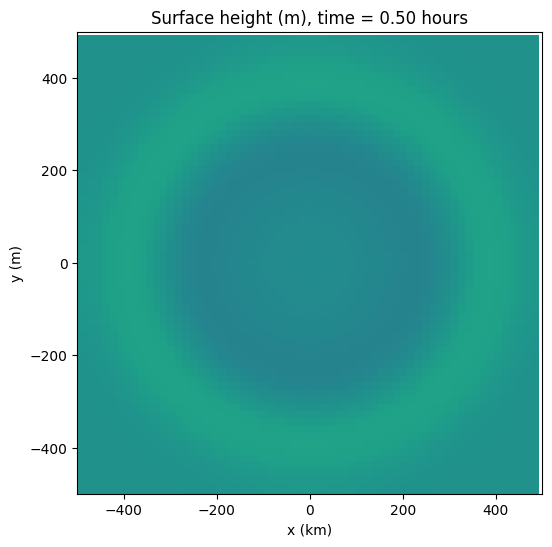

In [23]:
# create a figure and axes
fig = plt.figure(figsize=(6,6))

# Create arrays with the x and y coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y))

# Define an animation function
def drawframe(n):
    plt.clf # clear the figure before plotting the next frame
    height = plt.pcolor(X/(1*kilometer), Y/(1*kilometer), h_save[n,:,:], vmin=-1, vmax=1)
    # Specify the axis limits and labels
    plt.xlim((-Lx/2 / (1*kilometer),Lx/2 / (1*kilometer)))
    plt.ylim((-Ly/2 / (1*kilometer),Ly/2 / (1*kilometer)))
    plt.xlabel('x (km)')
    plt.ylabel('y (m)')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

---

### 2.3 Student investigation
<a id='section2pt3'></a>
Notice how the amplitude of the Tsunami wave decreases with distance from the source location. In the cell below, make a prediction for how the wave amplitude will vary as a function of distance from the origin (x=0, y=0) using conservation of energy. Then, make a plot or plots comparing your prediction for the wave amplitude compared with the results from the simulation.

Try out several different possible initial conditions for the surface height, $h$. How does the shape of the resulting waves change?



### Prediction:
For a circular wave spreading over water of constant depth, I expect the crest amplitude to decrease approximately as $A(r)\propto r^{-1/2}$, where $r=\sqrt{x^2+y^2}$ is the distance from the source.

For a small-amplitude shallow-water wave, the wave energy per unit area is proportional to $\rho gA^2$. At a distance $r$, the outgoing pulse occupies a ring with circumference $2\pi r$ and radial width $\Delta r$. If dissipation is negligible and the pulse width stays approximately constant, conservation of energy gives

$$
E \propto \rho g A(r)^2\,2\pi r\,\Delta r \approx \mathrm{constant}.
$$

Therefore, $rA(r)^2$ is approximately constant, giving $A(r)\propto r^{-1/2}$. This prediction applies once an outgoing ring has formed, away from the source and before waves returning through the periodic boundaries affect the measurement.


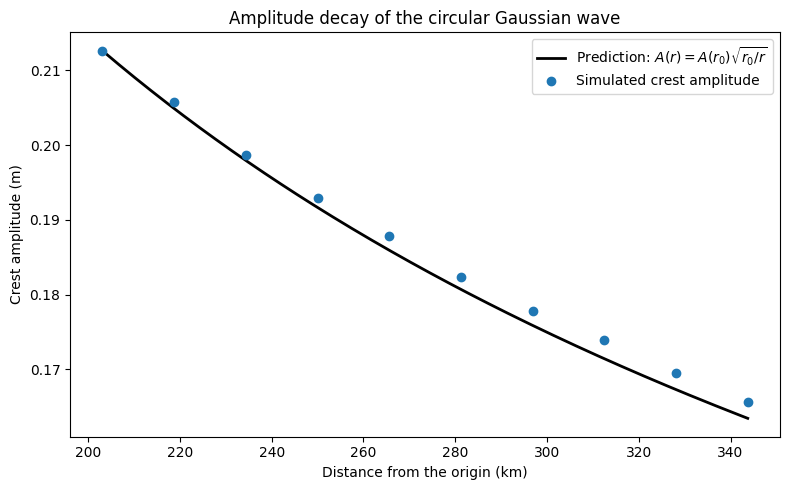

Measured exponent: -0.474
Predicted exponent: -0.500


In [27]:
import numpy as np
import matplotlib.pyplot as plt

x_grid = np.asarray(x).ravel()
y_grid = np.asarray(y).ravel()
times = np.asarray(t_save)
heights = np.asarray(h_save)

if heights.shape != (times.size, x_grid.size, y_grid.size):
    raise ValueError("Run Section 2.1 before this cell.")

j0 = np.argmin(np.abs(y_grid))
stations = (x_grid >= 2 * width) & (x_grid <= 3.5 * width)

r = x_grid[stations]
records = heights[:, stations, j0]
peak_frames = np.argmax(records, axis=0)
amplitude = np.max(records, axis=0)

valid = (peak_frames > 0) & (peak_frames < times.size - 1) & (amplitude > 0)
r = r[valid]
amplitude = amplitude[valid]

if r.size < 3:
    raise ValueError("Too few stations recorded a crest within the simulation time.")

r0 = r[0]
a0 = amplitude[0]
r_curve = np.linspace(r0, r[-1], 200)
a_curve = a0 * np.sqrt(r0 / r_curve)

exponent = np.polyfit(np.log(r / r0), np.log(amplitude / a0), 1)[0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    r_curve / kilometer, a_curve, "k-", lw=2,
    label=r"Prediction: $A(r)=A(r_0)\sqrt{r_0/r}$"
)
ax.plot(
    r / kilometer, amplitude, "o", color="tab:blue", ms=6,
    label="Simulated crest amplitude"
)
ax.set(
    xlabel="Distance from the origin (km)",
    ylabel="Crest amplitude (m)",
    title="Amplitude decay of the circular Gaussian wave"
)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Measured exponent: {exponent:.3f}")
print("Predicted exponent: -0.500")

###Discussion:
The crest amplitude decreases as the circular wave travels away from the origin. The simulated amplitudes closely follow the predicted $r^{-1/2}$ trend, consistent with the wave’s energy spreading around an expanding ring. Beyond the reference point, the simulated amplitudes lie slightly above the predicted curve, suggesting that the crest decays a little more slowly than expected over the distances shown.

---

### Exploration 1: Changing the shape of the initial surface

**Variable:** I change the coefficient of $y^2$ in the initial surface height from 1 to 4. The original circular Gaussian and the modified Gaussian are

$$
h_{\mathrm{circular}}(x,y,0)=A\exp\left(-\frac{x^2+y^2}{w^2}\right),
\qquad
h_{\mathrm{elliptical}}(x,y,0)=A\exp\left(-\frac{x^2+4y^2}{w^2}\right).
$$

Both disturbances are centred at the origin and have the same peak height, $A=1$ m. In the modified case, the width along $x$ remains $w=100$ km, while the width along $y$ decreases to $w/2=50$ km. The water depth and initial velocity are the same in both simulations. I compare the surface-height patterns at the same times using the same colour scale.


###Prediction:
The circular source should produce a ring that looks the same in every direction. The elliptical source starts narrower along $y$, so I expect a sharper wave profile along $y$ than along $x$, especially early in the simulation. The wave pattern should remain symmetric about both coordinate axes, but its height need not be the same at every point around the ring. Both cases have the same theoretical shallow-water speed, $c=\sqrt{gH}$, because the water depth is unchanged.

INFO:subsystems:Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 2.7e+01/s


2026-11-21 23:14:04,750 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 2.7e+01/s


INFO:subsystems:Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 1s, Rate: 3.5e+01/s


2026-11-21 23:14:04,827 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 1s, Rate: 3.5e+01/s


INFO:subsystems:Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 1s, Rate: 3.9e+01/s


2026-11-21 23:14:04,919 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 1s, Rate: 3.9e+01/s


... (12 outputs left out)

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 23:14:05,897 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x620 -pix_fmt rgba -framerate 10.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp4xa5xssc/temp.m4v


2026-11-21 23:14:05,900 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x620 -pix_fmt rgba -framerate 10.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp4xa5xssc/temp.m4v


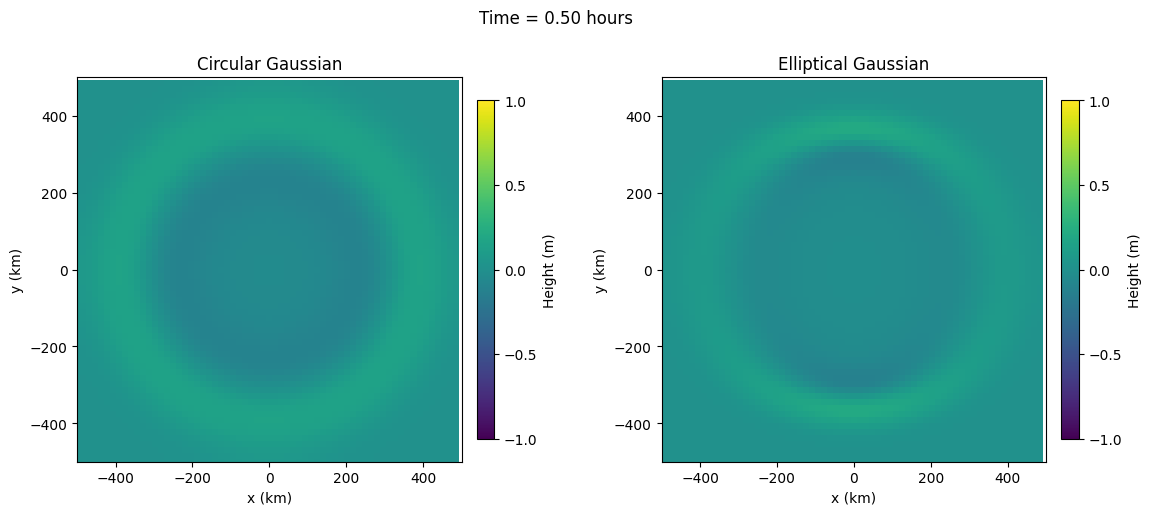

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import dedalus.public as dedalus

x_grid = np.asarray(x).ravel()
y_grid = np.asarray(y).ravel()
times = np.asarray(t_save)
circular_history = np.asarray(h_save)

if circular_history.shape != (times.size, x_grid.size, y_grid.size):
    raise ValueError("Run Section 2.1 before this cell.")

X, Y = np.meshgrid(x_grid, y_grid, indexing="ij")

def simulate_surface(initial_height):
    u_test = dist.Field(name="u_test", bases=(xbasis, ybasis))
    v_test = dist.Field(name="v_test", bases=(xbasis, ybasis))
    h_test = dist.Field(name="h_test", bases=(xbasis, ybasis))

    u_test["g"] = 0
    v_test["g"] = 0
    h_test["g"] = initial_height

    namespace = {
        "u_test": u_test,
        "v_test": v_test,
        "h_test": h_test,
        "dx": dx,
        "dy": dy,
        "g": g,
        "H": H
    }

    test_problem = dedalus.IVP([u_test, v_test, h_test], namespace=namespace)
    test_problem.add_equation(
        "dt(u_test) + g*dx(h_test) = -u_test*dx(u_test) - v_test*dy(u_test)"
    )
    test_problem.add_equation(
        "dt(v_test) + g*dy(h_test) = -u_test*dx(v_test) - v_test*dy(v_test)"
    )
    test_problem.add_equation(
        "dt(h_test) + H*(dx(u_test) + dy(v_test)) = "
        "-dx(h_test*u_test) - dy(h_test*v_test)"
    )

    test_solver = test_problem.build_solver(dedalus.RK222)
    history = [np.copy(h_test["g"])]

    for dt in np.diff(times):
        test_solver.step(float(dt))
        h_test.change_scales(1)
        history.append(np.copy(h_test["g"]))

    return np.asarray(history)

elliptical_initial = np.exp(-(X**2 + 4 * Y**2) / width**2)
elliptical_history = simulate_surface(elliptical_initial)

histories = [circular_history, elliptical_history]
names = ["Circular Gaussian", "Elliptical Gaussian"]

def plot_comparison(frame):
    fig = plt.figure(figsize=(12, 6.2))
    panels = fig.add_gridspec(
        1, 2,
        left=0.09, right=0.92,
        bottom=0.22, top=0.84,
        wspace=0.42
    )

    meshes = []

    for column, (history, name) in enumerate(zip(histories, names)):
        ax = fig.add_subplot(panels[0, column])
        mesh = ax.pcolormesh(
            x_grid / kilometer,
            y_grid / kilometer,
            history[frame].T,
            shading="nearest",
            cmap="viridis",
            vmin=-1,
            vmax=1
        )
        ax.set(
            title=name,
            xlabel="x (km)",
            ylabel="y (km)",
            xlim=(-Lx / (2 * kilometer), Lx / (2 * kilometer)),
            ylim=(-Ly / (2 * kilometer), Ly / (2 * kilometer)),
            aspect="equal"
        )

        color_axis = ax.inset_axes([1.04, 0.06, 0.045, 0.88])
        colorbar = fig.colorbar(
            mesh,
            cax=color_axis,
            ticks=[-1, -0.5, 0, 0.5, 1]
        )
        colorbar.set_label("Height (m)")
        meshes.append(mesh)

    title = fig.suptitle(f"Time = {times[frame] / hour:.2f} hours", y=0.95)
    return fig, meshes, title

fig_video, meshes, time_title = plot_comparison(0)

def drawframe(n):
    for mesh, history in zip(meshes, histories):
        mesh.set_array(history[n].T.ravel())

    time_title.set_text(f"Time = {times[n] / hour:.2f} hours")
    return (*meshes, time_title)

anim = animation.FuncAnimation(
    fig_video,
    drawframe,
    frames=len(times),
    interval=100,
    blit=False
)

plt.close(fig_video)
display(HTML(anim.to_html5_video()))

fig_final, _, _ = plot_comparison(-1)
plt.show()


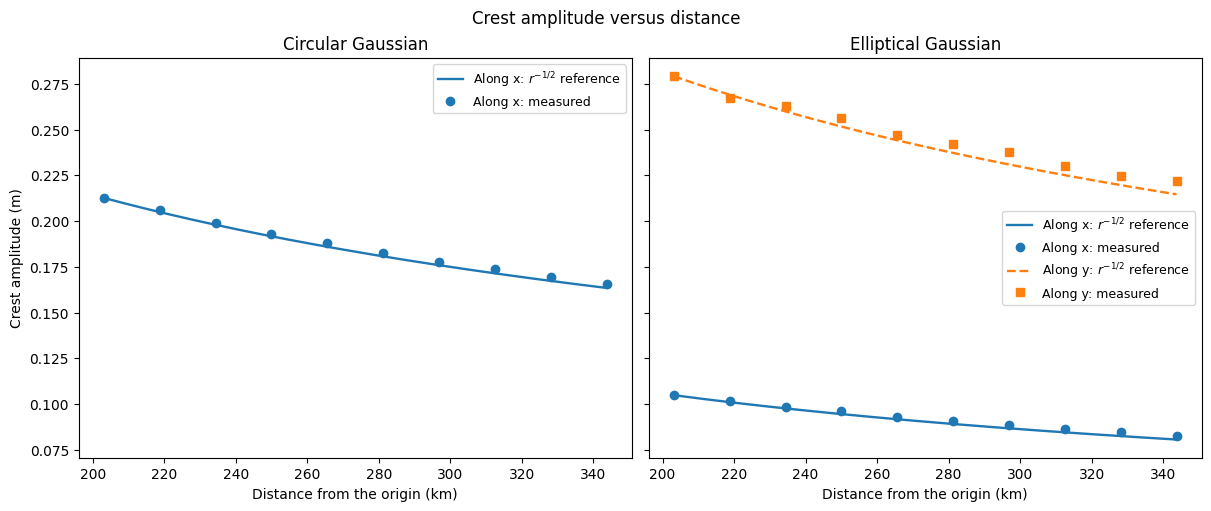

Circular Gaussian, along x:   -0.474
Elliptical Gaussian, along x: -0.451
Elliptical Gaussian, along y: -0.437
Reference exponent:          -0.500


In [32]:
import numpy as np
import matplotlib.pyplot as plt

ix0 = np.argmin(np.abs(x_grid))
iy0 = np.argmin(np.abs(y_grid))

def plot_decay(ax, distance, records, label, color, marker, linestyle):
    stations = (distance >= 2 * width) & (distance <= 3.5 * width)
    r = distance[stations]
    signals = records[:, stations]

    peak_frames = np.argmax(signals, axis=0)
    amplitude = np.max(signals, axis=0)
    valid = (
        (peak_frames > 0)
        & (peak_frames < signals.shape[0] - 1)
        & (amplitude > 0)
    )
    r = r[valid]
    amplitude = amplitude[valid]

    if r.size < 3:
        raise ValueError(f"Too few complete crest passages for {label}.")

    r0 = r[0]
    a0 = amplitude[0]
    r_line = np.linspace(r0, r[-1], 200)
    reference = a0 * np.sqrt(r0 / r_line)
    exponent = np.polyfit(np.log(r / r0), np.log(amplitude / a0), 1)[0]

    ax.plot(
        r_line / kilometer, reference,
        color=color, linestyle=linestyle, linewidth=1.7,
        label=rf"{label}: $r^{{-1/2}}$ reference"
    )
    ax.plot(
        r / kilometer, amplitude,
        color=color, marker=marker, linestyle="none", markersize=6,
        label=f"{label}: measured"
    )
    return exponent

fig, (ax_circular, ax_elliptical) = plt.subplots(
    1, 2, figsize=(12, 5), sharex=True, sharey=True,
    constrained_layout=True
)

p_circular = plot_decay(
    ax_circular, x_grid, circular_history[:, :, iy0],
    "Along x", "tab:blue", "o", "-"
)
p_ellipse_x = plot_decay(
    ax_elliptical, x_grid, elliptical_history[:, :, iy0],
    "Along x", "tab:blue", "o", "-"
)
p_ellipse_y = plot_decay(
    ax_elliptical, y_grid, elliptical_history[:, ix0, :],
    "Along y", "tab:orange", "s", "--"
)

ax_circular.set_title("Circular Gaussian")
ax_elliptical.set_title("Elliptical Gaussian")
ax_circular.set_ylabel("Crest amplitude (m)")

for ax in (ax_circular, ax_elliptical):
    ax.set_xlabel("Distance from the origin (km)")
    ax.legend(fontsize=9)

fig.suptitle("Crest amplitude versus distance")
plt.show()

print(f"Circular Gaussian, along x:   {p_circular:.3f}")
print(f"Elliptical Gaussian, along x: {p_ellipse_x:.3f}")
print(f"Elliptical Gaussian, along y: {p_ellipse_y:.3f}")
print("Reference exponent:          -0.500")

###Discussion 1:
The circular Gaussian produces an expanding ring with a fairly uniform crest. When the initial disturbance is made narrower along $y$, the wave still spreads outward, but the crest height varies around the ring. Two prominent arcs develop in the positive and negative $y$ directions, while the sides along $x$ are weaker. The amplitude plot confirms this pattern: the crests decay with distance along both axes, but they remain higher along $y$ than along $x$ at the same distance.

---

### Experiment 2: Increasing the width of the circular Gaussian

**Changed variable.** I increase the width of the initial surface disturbance from $w=100$ km to $1.5w=150$ km in both directions. The two initial height fields are

$$
h_{\mathrm{original}}(x,y,0)=A\exp\left(-\frac{x^2+y^2}{w^2}\right),
\qquad
h_{\mathrm{wider}}(x,y,0)=A\exp\left(-\frac{x^2+y^2}{(1.5w)^2}\right).
$$

Both sources are circular and centred at the origin. The peak height is $A=1$ m in both cases, and the water depth and initial velocity stay the same. The wider source has more initial wave energy because the surface is elevated over a larger area.

###Prediction:
Both sources are expected to produce circular wavefronts. The wider source should produce a broader crest: at a given time, the band of elevated water should extend over a greater radial distance. The wave speed should remain approximately the same because the water depth is unchanged. Once an outgoing ring has formed, its crest amplitude should decrease approximately as $r^{-1/2}$ in both cases. Over the same measurement interval, the wider source may show a larger departure from this prediction because the stations are closer to the source when distance is measured in units of its width.

INFO:subsystems:Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 6.2e+01/s


2026-11-21 23:27:21,521 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 6.2e+01/s


INFO:subsystems:Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 0s, Rate: 6.0e+01/s


2026-11-21 23:27:21,572 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 0s, Rate: 6.0e+01/s


INFO:subsystems:Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 6.0e+01/s


2026-11-21 23:27:21,638 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 0s, Rate: 6.0e+01/s


... (12 outputs left out)

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 23:27:22,773 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x620 -pix_fmt rgba -framerate 10.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp1namemdp/temp.m4v


2026-11-21 23:27:22,778 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x620 -pix_fmt rgba -framerate 10.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmp1namemdp/temp.m4v


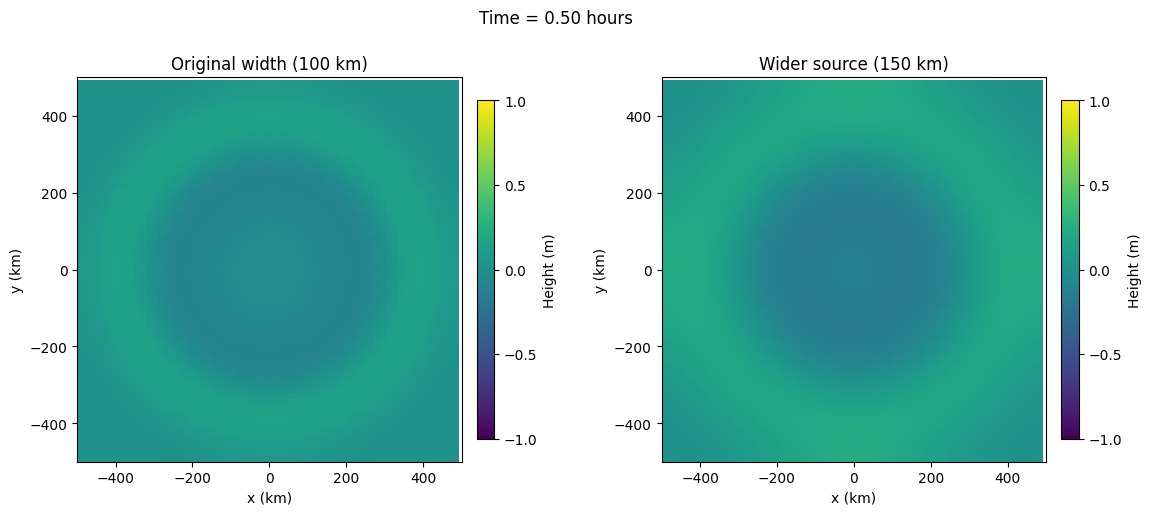

Original width (100 km): measured exponent = -0.474
Wider source (150 km): measured exponent = -0.471


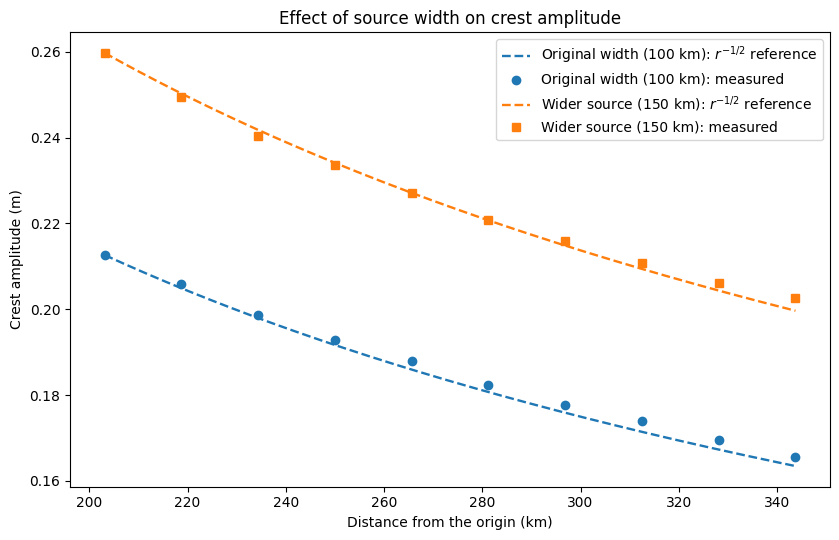

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

original_width = width
wider_width = 1.5 * original_width

wide_initial = np.exp(-(X**2 + Y**2) / wider_width**2)
wide_history = simulate_surface(wide_initial)

width_histories = [circular_history, wide_history]
width_labels = [
    f"Original width ({original_width / kilometer:.0f} km)",
    f"Wider source ({wider_width / kilometer:.0f} km)"
]

def plot_width_comparison(frame):
    fig = plt.figure(figsize=(12, 6.2))
    panels = fig.add_gridspec(
        1, 2,
        left=0.09, right=0.92,
        bottom=0.22, top=0.84,
        wspace=0.42
    )
    meshes = []

    for column, (history, label) in enumerate(zip(width_histories, width_labels)):
        ax = fig.add_subplot(panels[0, column])
        mesh = ax.pcolormesh(
            x_grid / kilometer,
            y_grid / kilometer,
            history[frame].T,
            shading="nearest",
            cmap="viridis",
            vmin=-1,
            vmax=1
        )
        ax.set(
            title=label,
            xlabel="x (km)",
            ylabel="y (km)",
            xlim=(-Lx / (2 * kilometer), Lx / (2 * kilometer)),
            ylim=(-Ly / (2 * kilometer), Ly / (2 * kilometer)),
            aspect="equal"
        )

        color_axis = ax.inset_axes([1.04, 0.06, 0.045, 0.88])
        colorbar = fig.colorbar(
            mesh, cax=color_axis, ticks=[-1, -0.5, 0, 0.5, 1]
        )
        colorbar.set_label("Height (m)")
        meshes.append(mesh)

    title = fig.suptitle(f"Time = {times[frame] / hour:.2f} hours", y=0.95)
    return fig, meshes, title

fig_video, width_meshes, width_title = plot_width_comparison(0)

def draw_width_frame(n):
    for mesh, history in zip(width_meshes, width_histories):
        mesh.set_array(history[n].T.ravel())

    width_title.set_text(f"Time = {times[n] / hour:.2f} hours")
    return (*width_meshes, width_title)

width_animation = animation.FuncAnimation(
    fig_video,
    draw_width_frame,
    frames=len(times),
    interval=100,
    blit=False
)

plt.close(fig_video)
display(HTML(width_animation.to_html5_video()))

fig_final, _, _ = plot_width_comparison(-1)
plt.show()

iy0 = np.argmin(np.abs(y_grid))
stations = (x_grid >= 2 * original_width) & (x_grid <= 3.5 * original_width)
r_stations = x_grid[stations]

crest_amplitudes = []
common_stations = np.ones(r_stations.size, dtype=bool)

for history in width_histories:
    records = history[:, stations, iy0]
    peak_frames = np.argmax(records, axis=0)
    amplitudes = np.max(records, axis=0)

    common_stations &= (
        (peak_frames > 0)
        & (peak_frames < len(times) - 1)
        & (amplitudes > 0)
    )
    crest_amplitudes.append(amplitudes)

r = r_stations[common_stations]

if r.size < 3:
    raise ValueError("Too few stations recorded complete crests in both simulations.")

r_line = np.linspace(r[0], r[-1], 200)
fig_amp, ax_amp = plt.subplots(figsize=(8.5, 5.5))

for amplitudes, label, color, marker in zip(
    crest_amplitudes, width_labels, ["tab:blue", "tab:orange"], ["o", "s"]
):
    measured = amplitudes[common_stations]
    reference = measured[0] * np.sqrt(r[0] / r_line)

    ax_amp.plot(
        r_line / kilometer, reference,
        color=color, linestyle="--", linewidth=1.7,
        label=rf"{label}: $r^{{-1/2}}$ reference"
    )
    ax_amp.plot(
        r / kilometer, measured,
        color=color, marker=marker, linestyle="none", markersize=6,
        label=f"{label}: measured"
    )

    exponent = np.polyfit(np.log(r / r[0]), np.log(measured / measured[0]), 1)[0]
    print(f"{label}: measured exponent = {exponent:.3f}")

ax_amp.set(
    xlabel="Distance from the origin (km)",
    ylabel="Crest amplitude (m)",
    title="Effect of source width on crest amplitude"
)
ax_amp.legend()
fig_amp.tight_layout()
plt.show()

###Discussion 2:
Increasing the source width preserves the circular symmetry of the wave but produces a broader band of elevated water around the ring. The wider source also produces a higher crest at every measured distance. This is consistent with the two sources having the same initial peak height while the wider disturbance extends over a larger area and therefore contains more initial wave energy. Despite the difference in crest height, both sets of measurements follow the $r^{-1/2}$ trend closely. Over the distances shown, changing the source width mainly affects the width and height of the crest, with little change in how its amplitude decays with distance.

## 3. Shallow water equations on a sphere

Of course the Earth isn't a flat plane. A great strength of Dedalus is its flexibility to solve equations in various geometries. The script below solves the 2D shallow water equations on a spherical shell, where the azimuth and colatitude are the independent variables. The colatitude is the complementary angle to the latitude such that the colatitude is $0^\circ$ at the North Pole, $90^\circ$ at the Equator, and $180^\circ$ at the South Pole. The spherical geometry also allows us to take into account the Earth's rotation in a realistic way.

Specifically, we will solve the following equations:
$$ \partial_t \mathbf{u} + g \nabla h + 2 \Omega \hat{\mathbf{z}} \times \mathbf{u} = -\mathbf{u} \cdot \nabla \mathbf{u} $$
$$ \partial_t + H \nabla \cdot \mathbf{u} = -\nabla \cdot (h \mathbf{u}) $$

where $\mathbf{u}$ is the velocity vector, $\Omega$ is the Earth's angular velocity (in radians per second), and $\hat{\mathbf{z}}$ is a unit vector aligned with the North Pole. Note that we have written the equations above in vector form. Dedalus includes vector calculus operators that make it very natural to solve equations like this without worrying about the particular form of the vector operators in a curvilinear coordinate system.

### 3.1  Dedalus script for 2D shallow water equations on a sphere

In [34]:
# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Define the simulation units. This is optional, but will help us keep track of units
meter = 1
kilometer = meter * 1e3
second = 1
minute = 60
hour = 3600
day = hour * 24

# Parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.37122e3 * kilometer
Omega = 2 * np.pi / (1 * day) # Earth's angular velocity in radians per second
g = 9.80616 * meter / second**2 # Gravitational acceleration
H = 4 * kilometer # Depth of the ocean
width = 2*np.pi*10/360 # Width of the initial Gaussian in radians
phi0 = np.pi # Longitude of the initial Gaussian height perturbation in radians
theta0 = np.pi/4 # Colatitude of the initial Gaussian height perturbation in radians

timestep = 600 * second
stop_sim_time = 10 * day

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude
lat = 360*(np.pi / 2 - theta)/(2*np.pi)  # latitude in degrees

# Fields
u = dist.VectorField(coords, name='u', bases=basis)
h = dist.Field(name='h', bases=basis)

# Operators
# First, create an operator to perform the cross product: "z x ", where z is the local vertical unit vector
# The "skew" operator performs a 90 degree rotation of a vector field,
# so that skew([u,v]) = [-v, u].  MulCosine multiplies by the cosine of the latitude
zcross = lambda A: dedalus.MulCosine(dedalus.skew(A))

# Set the initial conditions
h.change_scales(1) # Set values on regular grid
u.change_scales(1)
h['g'] = np.exp(-((phi-phi0)**2+(theta-theta0)**2)/width**2)  # Initialize the dependent variable c with a Gaussian function (note ** is the exponentiation operator)
# Set the initial velocity to zero
u['g'][0] = 0 # the x-component of the velocity
u['g'][1] = 0 # the y-component of the velocity

# Problem
problem = dedalus.IVP([u, h], namespace=locals())
problem.add_equation("dt(u) + g*grad(h) + 2*Omega*zcross(u) = - u@grad(u)")
problem.add_equation("dt(h) + H*div(u) = - div(h*u)")

# Solver
solver = problem.build_solver(dedalus.RK222)
solver.stop_sim_time = stop_sim_time

h.change_scales(1)
h_save = [np.copy(h['g'])]; t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        solver.step(timestep)
        if (solver.iteration-1) % 10 == 0:
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            h.change_scales(1)
            h_save.append(np.copy(h['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

h_save = np.array(h_save)

INFO:subsystems:Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 1s, Rate: 5.0e+01/s


2026-11-21 23:31:32,979 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 1s, Rate: 5.0e+01/s


INFO:subsystems:Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 6.6e+01/s


2026-11-21 23:31:33,065 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 6.6e+01/s


INFO:subsystems:Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 6.8e+01/s


2026-11-21 23:31:33,166 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 6.8e+01/s


... (316 outputs left out)

INFO:solvers:CPU time (iter 10-end): 0.02365 cpu-hr


2026-11-21 23:33:04,535 solvers 0/1 INFO :: CPU time (iter 10-end): 0.02365 cpu-hr


INFO:solvers:Speed: 4.062e+05 mode-stages/cpu-sec


2026-11-21 23:33:04,536 solvers 0/1 INFO :: Speed: 4.062e+05 mode-stages/cpu-sec


### 3.2  Plotting
The code below will make a movie of the height as a function of x and y

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


2026-11-21 23:33:22,547 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>


INFO:matplotlib.animation:MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpzh67hwv2/temp.m4v


2026-11-21 23:33:22,552 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpzh67hwv2/temp.m4v


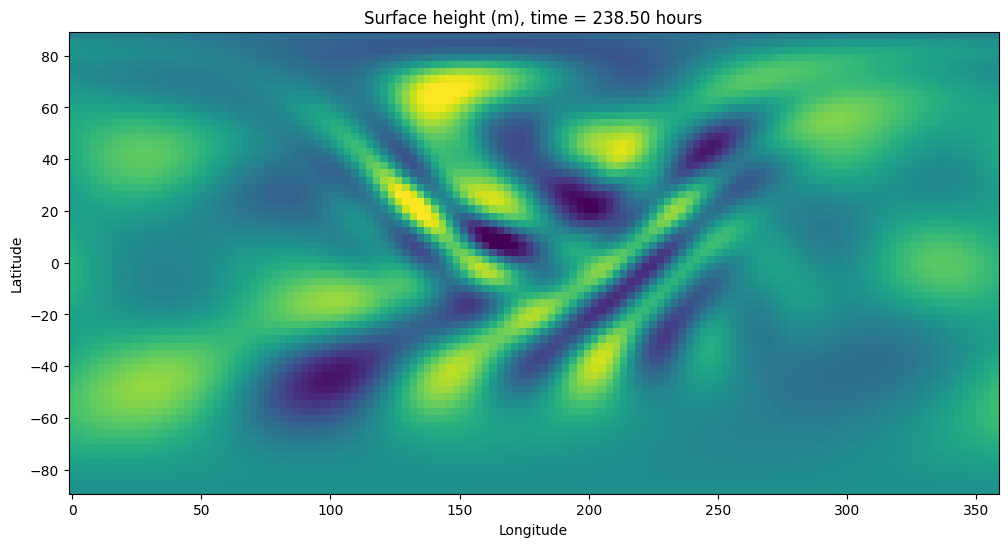

In [35]:
# create a figure and axes
fig = plt.figure(figsize=(12,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(np.pi/2 - theta)*360/2/np.pi, np.squeeze(phi)*360/2/np.pi)

# Define an animation function
def drawframe(n):
    plt.clf()
    height = plt.pcolor(Y, X, h_save[n,:,:], vmin=-0.1, vmax=0.1)
    # Specify the axis limits and labels
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Surface height (m), time = {0:.2f} hours'.format(t_save[n]/(1*hour)))
    return (height,)

from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=len(t_save), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 3.3 Student investigation
<a id='section3pt3'></a>
Create a virtual tide gauge by sampling the height at a point at a latitude of 45ºN and longitude of 90ºW and plot the timeseries of the height at this point in the cells below. You should modifty the code to save the height more often so that you can clearly see the shape of the wave. Notice that as the waves propagate around the Earth, their shape changes. Discuss physical mechanisms that might cause the shape of the wave to change as the wave propagates.

INFO:subsystems:Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 11s, Rate: 5.7e+00/s


2026-11-21 23:43:25,097 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 11s, Rate: 5.7e+00/s


INFO:subsystems:Building subproblem matrices 7/63 (~11%) Elapsed: 1s, Remaining: 4s, Rate: 1.3e+01/s


2026-11-21 23:43:25,454 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 1s, Remaining: 4s, Rate: 1.3e+01/s


INFO:subsystems:Building subproblem matrices 14/63 (~22%) Elapsed: 1s, Remaining: 3s, Rate: 1.9e+01/s


2026-11-21 23:43:25,655 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 1s, Remaining: 3s, Rate: 1.9e+01/s


... (12 outputs left out)

INFO:subsystems:Building subproblem matrices 63/63 (~100%) Elapsed: 2s, Remaining: 0s, Rate: 3.5e+01/s


2026-11-21 23:43:26,698 subsystems 0/1 INFO :: Building subproblem matrices 63/63 (~100%) Elapsed: 2s, Remaining: 0s, Rate: 3.5e+01/s


INFO:solvers:Simulation stop time reached.


2026-11-21 23:44:53,594 solvers 0/1 INFO :: Simulation stop time reached.


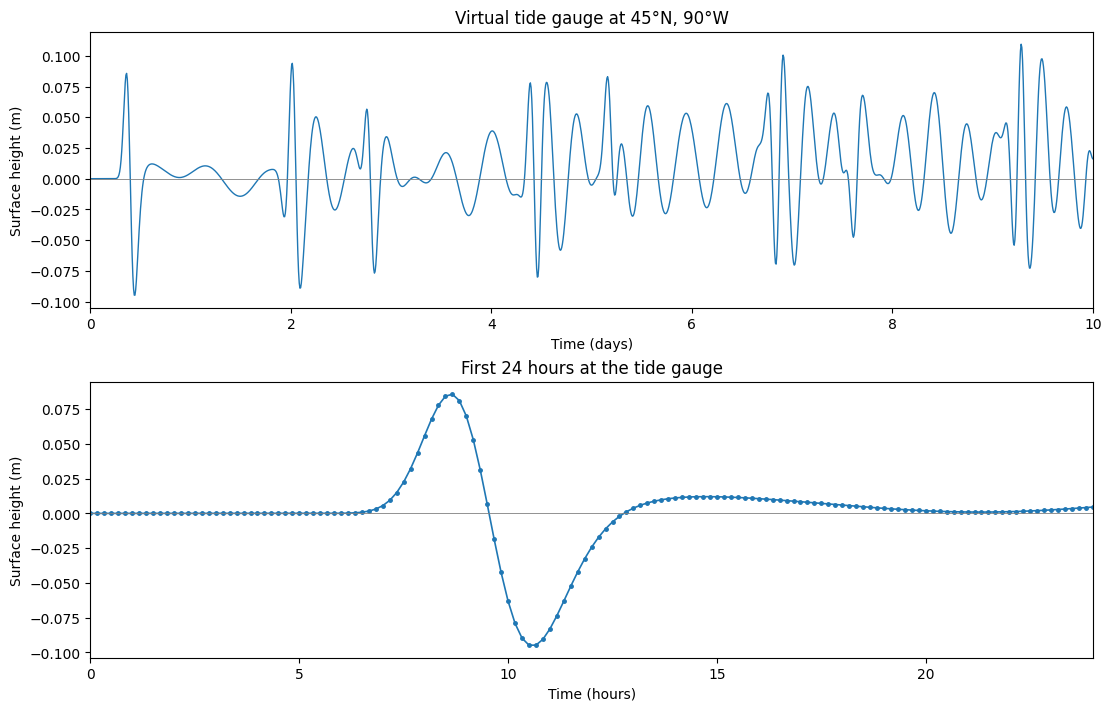

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as dedalus

gauge_dt = 600 * second
gauge_stop = 10 * day

u_gauge = dist.VectorField(coords, name="u_gauge", bases=basis)
h_gauge = dist.Field(name="h_gauge", bases=basis)

u_gauge["g"] = 0
h_gauge["g"] = np.asarray(h_save[0])

gauge_namespace = {
    "u_gauge": u_gauge,
    "h_gauge": h_gauge,
    "g": g,
    "H": H,
    "Omega": Omega,
    "zcross": zcross
}

gauge_problem = dedalus.IVP([u_gauge, h_gauge], namespace=gauge_namespace)
gauge_problem.add_equation(
    "dt(u_gauge) + g*grad(h_gauge) + 2*Omega*zcross(u_gauge) "
    "= -u_gauge@grad(u_gauge)"
)
gauge_problem.add_equation(
    "dt(h_gauge) + H*div(u_gauge) = -div(h_gauge*u_gauge)"
)

gauge_solver = gauge_problem.build_solver(dedalus.RK222)
gauge_solver.stop_sim_time = gauge_stop

longitude = np.mod(np.degrees(np.asarray(phi).ravel()), 360)
latitude = 90 - np.degrees(np.asarray(theta).ravel())

lon_distance = np.abs((longitude - 270 + 180) % 360 - 180)
gauge_lon_index = np.argmin(lon_distance)
lat_order = np.argsort(latitude)
sorted_latitude = latitude[lat_order]

def read_tide_gauge():
    h_gauge.change_scales(1)
    profile = h_gauge["g"][gauge_lon_index, lat_order]
    return float(np.interp(45.0, sorted_latitude, profile))

gauge_times = [gauge_solver.sim_time]
gauge_heights = [read_tide_gauge()]

while gauge_solver.proceed:
    gauge_solver.step(gauge_dt)
    gauge_times.append(gauge_solver.sim_time)
    gauge_heights.append(read_tide_gauge())

gauge_times = np.asarray(gauge_times)
gauge_heights = np.asarray(gauge_heights)

time_days = gauge_times / day
time_hours = gauge_times / hour
first_day = time_hours <= 24

fig, (ax_full, ax_zoom) = plt.subplots(
    2, 1, figsize=(11, 7), constrained_layout=True
)

ax_full.plot(time_days, gauge_heights, color="tab:blue", lw=1)
ax_full.axhline(0, color="0.5", lw=0.6)
ax_full.set(
    xlim=(0, time_days[-1]),
    xlabel="Time (days)",
    ylabel="Surface height (m)",
    title="Virtual tide gauge at 45°N, 90°W"
)

ax_zoom.plot(
    time_hours[first_day], gauge_heights[first_day],
    color="tab:blue", lw=1.2, marker="o", ms=2.5
)
ax_zoom.axhline(0, color="0.5", lw=0.6)
ax_zoom.set(
    xlim=(0, 24),
    xlabel="Time (hours)",
    ylabel="Surface height (m)",
    title="First 24 hours at the tide gauge"
)

plt.show()

###Discussion:
At the virtual tide gauge, the first arrival has a clear shape: the surface rises to a crest around hour 9, falls into a slightly deeper trough, and then returns gradually towards its resting level. Over the following days, the spacing and height of the crests vary. Some later crests are higher than the first, so the amplitude at the gauge does not decrease steadily.

The spherical geometry helps explain this pattern. A wavefront spreads as it travels away from the source and converges again as it approaches the opposite side of the planet. As waves continue around the globe, signals that have travelled different distances can overlap at the gauge. Two arriving crests can reinforce each other, while a crest arriving with a trough can partly cancel it. Earth’s rotation can also change the relative timing of different wave components, further altering the shape of the recorded wave train.

---

In the simulation above, the Tsunami wave travels around the planet many times. In reality, the waves will partially dissipate when they reach shorelines. In the spherical shallow water equation code above (or in a new code block below), add a forcing term to the shallow water equations that damps the waves for longitudes larger than $\pm 90^\circ$. Specifically, add a forcing function to the right hand side of the height equation of the following form:

$$ - (1/\tau) f(\phi) h$$

where

$$ f(\phi) = \frac{1}{2}\left(1+tanh\left(\frac{\phi-3\pi/2}{\pi/10}\right)\right) + \frac{1}{2}\left(1-tanh\left(\frac{\phi-\pi/2}{\pi/10}\right)\right) $$

and $\phi$ is the longitude in radians and $\tau$ is a damping timescale. A timescale of $\tau=0.1$ days should be sufficient to damp the waves.

With this damping term active, much more slowly propagating waves should be visible. These are shallow water Rossby waves. Estimate the east/west phase speed of these Rossby waves and compare them with the phase speed that you can infer from the simulation by plotting the height, $h$, as a function of longitude and time. Discuss the spatial structure of the Rossby waves and any discrepancies that you see between your estimated and measured phase speeds.

###Prediction:

Add the term $-M(\phi)h/\tau$ to the height equation, using the prescribed longitude-dependent mask $M(\phi)$ and a damping timescale of $\tau=0.1$ days. This reduces the amplitude of waves entering the damped region and makes slower signals easier to identify.

At latitude $\lambda=45^\circ$N, the local shallow-water Rossby-wave dispersion relation gives the east–west phase speed

$$
c_x=\frac{\omega}{k}
=-\frac{\beta}{k^2+l^2+L_D^{-2}},
\qquad
\beta=\frac{2\Omega\cos\lambda}{R},
\qquad
L_D=\frac{\sqrt{gH}}{2\Omega\sin\lambda}.
$$

Here, $k$ and $l$ are the zonal and meridional wavenumbers. Taking eastward as positive, the negative sign predicts westward propagation. The initial Gaussian contains a range of spatial scales, so there is no single theoretical speed for the entire disturbance. For an order-of-magnitude estimate, I use $k\sim1/L_x$ and $l\sim1/L_y$, where $L_x=R\cos\lambda\,w$ and $L_y=Rw$ are the physical widths of the initial Gaussian and $w$ is its angular width in radians.

INFO:subsystems:Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 4s, Rate: 1.4e+01/s


2026-11-22 00:52:37,295 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 4s, Rate: 1.4e+01/s


INFO:subsystems:Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 2s, Rate: 3.7e+01/s


2026-11-22 00:52:37,412 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 2s, Rate: 3.7e+01/s


INFO:subsystems:Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s


2026-11-22 00:52:37,522 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s


... (12 outputs left out)

INFO:subsystems:Building subproblem matrices 63/63 (~100%) Elapsed: 1s, Remaining: 0s, Rate: 6.2e+01/s


2026-11-22 00:52:38,235 subsystems 0/1 INFO :: Building subproblem matrices 63/63 (~100%) Elapsed: 1s, Remaining: 0s, Rate: 6.2e+01/s


INFO:solvers:Simulation stop time reached.


2026-11-22 00:54:14,585 solvers 0/1 INFO :: Simulation stop time reached.


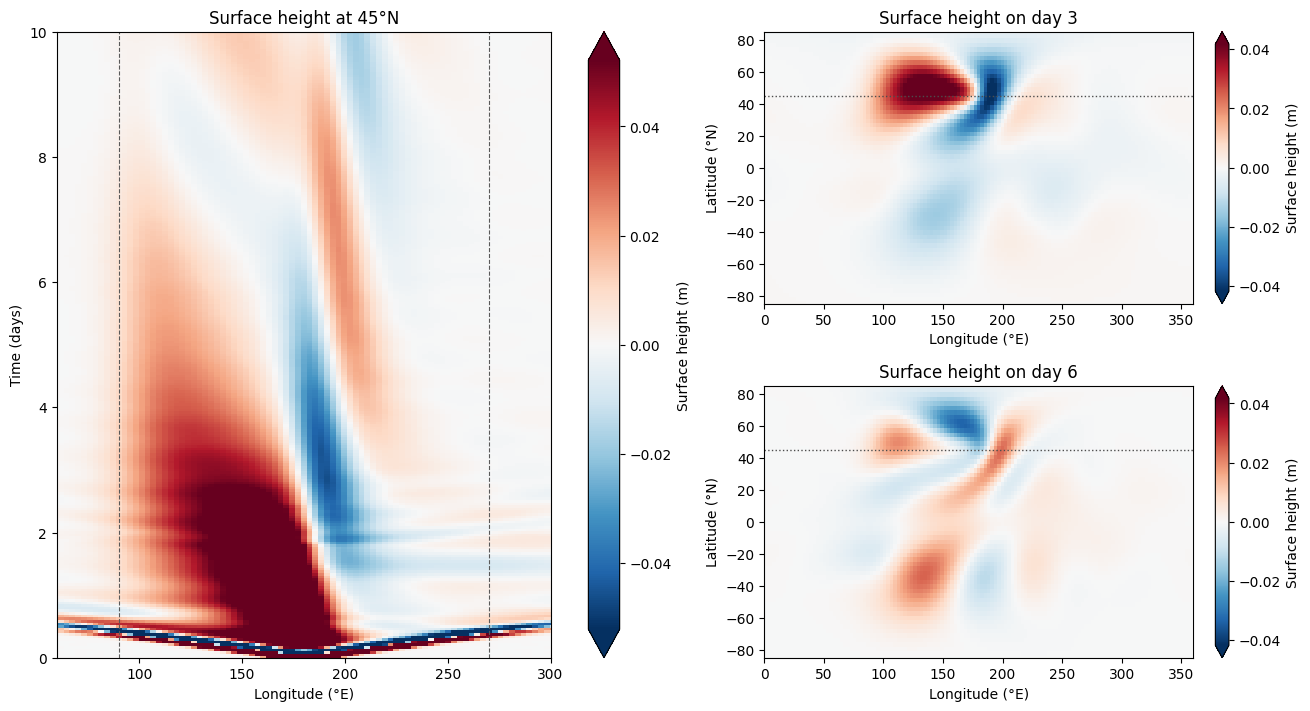

Source-scale theoretical phase speed: -5.99 m/s


In [37]:
import numpy as np
import matplotlib.pyplot as plt
import dedalus.public as dedalus

tau = 0.1 * day
rossby_dt = 600 * second
rossby_stop = 10 * day

u_r = dist.VectorField(coords, name="u_r", bases=basis)
h_r = dist.Field(name="h_r", bases=basis)
mask_r = dist.Field(name="mask_r", bases=basis)

u_r["g"] = 0
h_r["g"] = np.asarray(h_save[0])
mask_r["g"] = (
    0.5 * (1 + np.tanh((phi - 3 * np.pi / 2) / (np.pi / 10)))
    + 0.5 * (1 - np.tanh((phi - np.pi / 2) / (np.pi / 10)))
)

rossby_namespace = {
    "u_r": u_r,
    "h_r": h_r,
    "mask_r": mask_r,
    "tau": tau,
    "g": g,
    "H": H,
    "Omega": Omega,
    "zcross": zcross
}

rossby_problem = dedalus.IVP([u_r, h_r], namespace=rossby_namespace)
rossby_problem.add_equation(
    "dt(u_r) + g*grad(h_r) + 2*Omega*zcross(u_r) = -u_r@grad(u_r)"
)
rossby_problem.add_equation(
    "dt(h_r) + H*div(u_r) = -div(h_r*u_r) - mask_r*h_r/tau"
)

rossby_solver = rossby_problem.build_solver(dedalus.RK222)
rossby_solver.stop_sim_time = rossby_stop

lon_deg = np.degrees(np.asarray(phi).ravel()) % 360
lat_deg = 90 - np.degrees(np.asarray(theta).ravel())
lat_order = np.argsort(lat_deg)
lat_sorted = lat_deg[lat_order]
target_lat = 45.0

upper = np.searchsorted(lat_sorted, target_lat)
lower = upper - 1
weight = (target_lat - lat_sorted[lower]) / (lat_sorted[upper] - lat_sorted[lower])
j_lower, j_upper = lat_order[[lower, upper]]

def latitude_section(field):
    return (
        (1 - weight) * field[:, j_lower]
        + weight * field[:, j_upper]
    ).copy()

rossby_times = [0.0]
rossby_sections = [latitude_section(h_r["g"])]
map_days = [3, 6]
rossby_maps = {}

while rossby_solver.proceed:
    rossby_solver.step(rossby_dt)

    if rossby_solver.iteration % 6 == 0 or not rossby_solver.proceed:
        h_r.change_scales(1)
        field = h_r["g"]
        current_time = rossby_solver.sim_time
        rossby_times.append(current_time)
        rossby_sections.append(latitude_section(field))

        for d in map_days:
            if d not in rossby_maps and current_time >= d * day:
                rossby_maps[d] = field.copy()

rossby_days = np.asarray(rossby_times) / day
rossby_sections = np.asarray(rossby_sections)

lat_rad = np.radians(target_lat)
f0 = 2 * Omega * np.sin(lat_rad)
beta = 2 * Omega * np.cos(lat_rad) / R
deformation_radius = np.sqrt(g * H) / f0

source_width_x = R * np.cos(lat_rad) * width
source_width_y = R * width
k_est = 1 / source_width_x
l_est = 1 / source_width_y
c_est = -beta / (k_est**2 + l_est**2 + deformation_radius**-2)

late = rossby_days >= 2
interior = (lon_deg >= 90) & (lon_deg <= 270)
section_limit = np.percentile(np.abs(rossby_sections[late][:, interior]), 98)
map_limit = max(np.percentile(np.abs(rossby_maps[d]), 99) for d in map_days)

def draw_hovmoller(ax):
    mesh = ax.pcolormesh(
        lon_deg, rossby_days, rossby_sections,
        shading="auto", cmap="RdBu_r",
        vmin=-section_limit, vmax=section_limit
    )
    ax.axvline(90, color="0.35", ls="--", lw=0.8)
    ax.axvline(270, color="0.35", ls="--", lw=0.8)
    ax.set(
        xlim=(60, 300), ylim=(0, rossby_days[-1]),
        xlabel="Longitude (°E)", ylabel="Time (days)",
        title="Surface height at 45°N"
    )
    return mesh

fig = plt.figure(figsize=(13, 7), constrained_layout=True)
grid = fig.add_gridspec(2, 2, width_ratios=[1.15, 1])
ax_time = fig.add_subplot(grid[:, 0])
mesh_time = draw_hovmoller(ax_time)
fig.colorbar(mesh_time, ax=ax_time, label="Surface height (m)", extend="both")

for row, d in enumerate(map_days):
    ax = fig.add_subplot(grid[row, 1])
    mesh_map = ax.pcolormesh(
        lon_deg, lat_sorted, rossby_maps[d][:, lat_order].T,
        shading="auto", cmap="RdBu_r", vmin=-map_limit, vmax=map_limit
    )
    ax.axhline(target_lat, color="0.3", ls=":", lw=1)
    ax.set(
        xlim=(0, 360), ylim=(-85, 85),
        xlabel="Longitude (°E)", ylabel="Latitude (°N)",
        title=f"Surface height on day {d}"
    )
    fig.colorbar(mesh_map, ax=ax, label="Surface height (m)", extend="both")

plt.show()
print(f"Source-scale theoretical phase speed: {c_est:.2f} m/s")

## 4. Optional further investigations

* In the example of the shallow water equations on a sphere, introduce bathymetry by making $H$ a function of latitude and longitude. Make sure that you modify the equations in Dedalus appropriately. How do the waves behave when they encounter shallow water (e.g. a localized seamount)?

* It is quite difficult to simulate changing sea level (sometimes called wetting and drying), which is why the examples above do not include land. However, we can estimate the distance that a Tsunami will propagate using physical and dimensional arguments. Consider, for example, a flat, sloping beach. In the absence of energy dissipation, estimate the distance that a wave will propagate onshore. How could you modify this estimate to include energy dissipation (or drag)?